# Pruebas por etapa — estructuras propias vs. Python

Pruebas de correctitud, tiempos y memoria de las estructuras de cada etapa, comparadas con la
implementación de Python o la alternativa exacta/simple cuando aplica.

**Regla:** este notebook solo importa los módulos de etapa (`pipeline_eda.etapaN_*`) y `evento`;
nunca el orquestador. Cada sección se puede correr sola después de las dos celdas de setup.

In [23]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Busca hacia arriba la carpeta que contiene pipeline_eda/, sin depender del cwd del kernel.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline_eda").is_dir())
sys.path.insert(0, str(RAIZ))
CSV_REAL = RAIZ / "data" / "2019-Oct-10M.csv"

Failed to reload module 'pipeline_eda.evento' from file '/Users/carlosandres/Developer/utec-proyecto-eda/pipeline_eda/evento.py'
Traceback (most recent call last):
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 625, in superreload
    update_generic(old_obj, new_obj)
    ~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 451, in update_generic
    update(a, b)
    ~~~~~~^^^^^^
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 419, in update_class
    update_instances(old, new)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


[autoreload of pipeline_eda.evento failed: Traceback (most recent call last):
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 625, in superreload
    update_generic(old_obj, new_obj)
    ~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 451, in update_generic
    update(a, b)
    ~~~~~~^^^^^^
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 419, in update_class
    update_instances(old, new)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/Users/carlosandres/.local/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 377, in update_instances
    object.__setattr__(ref, "__class__"

## Herramientas de medición

- `medir(fn, reps)`: promedio y desviación estándar de `reps` ejecuciones.
- `memoria_pico(fn)`: memoria pico que reserva `fn()`, con `tracemalloc` (lo que existía antes no cuenta).
- `graficar_loglog(resultados, ...)`: escalabilidad log-log con pendientes de referencia.

In [24]:
import bisect
import math
import platform
import random
import statistics
import time
import tracemalloc
from collections import deque
from itertools import islice

import matplotlib.pyplot as plt

SEED = 42
print(platform.platform(), "| Python", platform.python_version(), "| seed", SEED)


def medir(fn, reps):
    """Ejecuta fn() `reps` veces; devuelve (promedio, desviación estándar) en segundos."""
    tiempos = []
    for _ in range(reps):
        inicio = time.perf_counter()
        fn()
        tiempos.append(time.perf_counter() - inicio)
    return statistics.mean(tiempos), (statistics.stdev(tiempos) if reps > 1 else 0.0)


def memoria_pico(fn):
    """Memoria pico (bytes) reservada durante fn()."""
    tracemalloc.start()
    try:
        fn()
        return tracemalloc.get_traced_memory()[1]
    finally:
        tracemalloc.stop()


REFERENCIAS = {"log n": math.log2, "n": lambda n: n, "n log n": lambda n: n * math.log2(n)}


def graficar_loglog(resultados, titulo, referencias=(), unidad="s"):
    """resultados: {nombre: {n: valor}}. Las referencias se anclan al primer punto de la primera serie."""
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for nombre, serie in resultados.items():
        ns = sorted(serie)
        ax.loglog(ns, [serie[n] for n in ns], "o-", label=nombre)
    base = next(iter(resultados.values()))
    ns = sorted(base)
    for estilo, ref in zip((":", "--", "-."), referencias):
        f = REFERENCIAS[ref]
        ax.loglog(ns, [base[ns[0]] * f(n) / f(ns[0]) for n in ns], estilo, color="gray", label=f"O({ref})")
    ax.set_xlabel("n")
    ax.set_ylabel(unidad)
    ax.set_title(titulo)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    plt.show()

macOS-26.6.1-arm64-arm-64bit-Mach-O | Python 3.14.4 | seed 42


## Etapa 0 — Ingesta y buffer: `leer_csv`, `ColaFIFO` e `Ingesta`

### 0.1 Correctitud de `ColaFIFO`
Operaciones al azar contra `collections.deque`, con y sin capacidad.

In [25]:
from pipeline_eda.etapa0_ingesta import ColaFIFO, Ingesta, leer_csv

rng = random.Random(SEED)
for capacidad in (None, 1, 7, 100):
    cola, ref = ColaFIFO(capacidad), deque()
    for _ in range(20_000):
        op = rng.random()
        if op < 0.5:
            x = rng.random()
            entro = cola.encolar(x)
            assert entro == (capacidad is None or len(ref) < capacidad)  # False = backpressure
            if entro:
                ref.append(x)
        elif op < 0.8:
            if ref:
                assert cola.desencolar() == ref.popleft()
            else:
                try:
                    cola.desencolar()
                    raise AssertionError("debió lanzar IndexError")
                except IndexError:
                    pass
        else:
            k = rng.randint(0, 10)
            assert cola.desencolar_lote(k) == [ref.popleft() for _ in range(min(k, len(ref)))]
        assert len(cola) == len(ref)
print("ColaFIFO == deque (encolar, desencolar, desencolar_lote y capacidad)")

ColaFIFO == deque (encolar, desencolar, desencolar_lote y capacidad)


### 0.2 `Ingesta`: lotes y backpressure
El orden se conserva y los lotes tienen `tam_lote` eventos. Si la capacidad es menor que el lote, el
productor encuentra el buffer lleno (bloqueo) y se entrega lo acumulado.

In [26]:
for capacidad, tam_lote in ((50_000, 10), (3, 10), (None, 4), (10, 10)):
    ing = Ingesta(capacidad, tam_lote, sintetizar=False)  # solo el buffer
    lotes_e0 = list(ing.lotes(range(103)))
    assert [x for lote in lotes_e0 for x in lote] == list(range(103))
    tam = min(tam_lote, capacidad) if capacidad else tam_lote
    assert all(len(lote) == tam for lote in lotes_e0[:-1]) and 0 < len(lotes_e0[-1]) <= tam
    m = ing.metricas()
    print(f"capacidad={capacidad!s:>6} tam_lote={tam_lote:>3}  lotes={m['lotes']:>3}  "
          f"ocupación máx={m['ocupacion_max']:>3}  bloqueos={m['bloqueos']}")

capacidad= 50000 tam_lote= 10  lotes= 11  ocupación máx= 10  bloqueos=0
capacidad=     3 tam_lote= 10  lotes= 35  ocupación máx=  3  bloqueos=34
capacidad=  None tam_lote=  4  lotes= 26  ocupación máx=  4  bloqueos=0
capacidad=    10 tam_lote= 10  lotes= 11  ocupación máx= 10  bloqueos=0


### 0.3 `leer_csv` con datos reales
Tipos del contrato (`datetime` en UTC, int, float, `None`) y throughput de la etapa (lectura + buffer) sobre 1M de filas.

In [27]:
from datetime import datetime

stats = {}
primeros = list(leer_csv(CSV_REAL, limite=3, stats=stats))
for ev in primeros:
    print(ev)
assert all(isinstance(ev.event_time, datetime) and ev.event_time.tzinfo is not None and isinstance(ev.price, float) for ev in primeros)


def ingerir(n):
    ing = Ingesta(capacidad=50_000, tam_lote=10_000)
    for _ in ing.lotes(leer_csv(CSV_REAL, limite=n)):
        pass
    return ing


N_E0 = 1_000_000
prom, desv = medir(lambda: ingerir(N_E0), 3)
print(f"{N_E0:,} filas: {prom:.2f} s ± {desv:.2f}  ({N_E0 / prom:,.0f} eventos/s)")
ingerir(N_E0).metricas()

TypeError: descriptor 'event_time' for 'Event' objects doesn't apply to a 'Event' object

### 0.4 Componente sintético
Determinista con `SEMILLA`; `order_id` = sesión y un solo `tipo_envio` por orden; las ráfagas usan
tarjetas robadas (solo una parte señalada). Se compara la etapa 1 contra `is_dup`.

In [ ]:
from collections import Counter

from pipeline_eda.etapa0_ingesta import Sintetizador
from pipeline_eda.etapa1_preproceso import Preprocesador

N_SINT = 1_000_000
firma = lambda e: (e.event_time, e.event_type, e.product_id, e.user_id, e.card_id, e.tipo_envio, e.is_dup, e.is_fraud)
sint = Sintetizador()
stream = list(sint.flujo(leer_csv(CSV_REAL, limite=N_SINT)))
assert [firma(e) for e in stream] == [firma(e) for e in Sintetizador().flujo(leer_csv(CSV_REAL, limite=N_SINT))]

compras = [e for e in stream if e.event_type == "purchase" and not e.is_fraud]
envio_por_orden = {}
for e in compras:
    assert e.order_id == e.user_session and e.card_id is not None
    assert envio_por_orden.setdefault(e.order_id, e.tipo_envio) == e.tipo_envio
fraude = [e for e in stream if e.is_fraud]
assert all(e.card_id in sint.tarjetas_robadas for e in fraude)
print(f"{len(stream):,} eventos de {N_SINT:,} reales", sint.metricas())
print("tipo de envío por orden:", dict(Counter(envio_por_orden.values())))
print(f"intentos de fraude: {len(fraude)}, con tarjeta señalada: {sum(e.card_id in sint.senaladas for e in fraude)}")

# Etapa 1 contra la verdad de referencia
e0, e1 = Ingesta(50_000, 10_000), Preprocesador(100_000)
emitidos = [ev for lote in e0.lotes(leer_csv(CSV_REAL, limite=N_SINT)) for ev in e1.procesar(lote)]
m = e1.metricas()
print(f"is_dup en el stream: {sum(e.is_dup for e in stream):,} | descartados por la etapa 1: "
      f"{m['duplicados_lote'] + m['duplicados_ventana']:,} | is_dup que pasaron (más lejos que la ventana): "
      f"{sum(e.is_dup for e in emitidos)}")

### 0.5 `ColaFIFO` vs `deque` vs `list.pop(0)`
Encolar n elementos y luego desencolarlos todos. `list.pop(0)` corre los n−1 elementos restantes en
cada llamada (O(n²) en total), así que solo se mide hasta 100K.

n=    1,000  ColaFIFO       0.00022 s ± 0.00002  (100 reps)
n=    1,000  deque          0.00004 s ± 0.00000  (100 reps)
n=    1,000  list.pop(0)    0.00011 s ± 0.00002  (100 reps)
n=   10,000  ColaFIFO       0.00298 s ± 0.00250  (100 reps)
n=   10,000  deque          0.00050 s ± 0.00002  (100 reps)
n=   10,000  list.pop(0)    0.00614 s ± 0.00014  (100 reps)
n=  100,000  ColaFIFO       0.02911 s ± 0.00710  (5 reps)
n=  100,000  deque          0.00519 s ± 0.00027  (5 reps)
n=  100,000  list.pop(0)    0.78220 s ± 0.00313  (5 reps)
n=1,000,000  ColaFIFO       0.30393 s ± 0.04174  (3 reps)
n=1,000,000  deque          0.05458 s ± 0.00100  (3 reps)


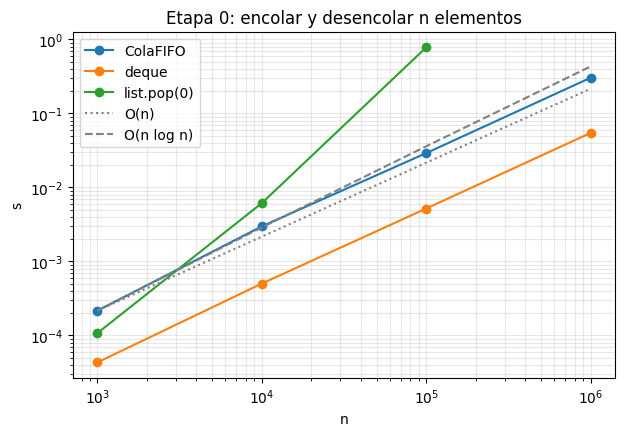

In [ ]:
TAMANOS_E0 = [1_000, 10_000, 100_000, 1_000_000]
REPS_E0 = {1_000: 100, 10_000: 100, 100_000: 5, 1_000_000: 3}


def con_cola_fifo(n):
    cola = ColaFIFO()
    for i in range(n):
        cola.encolar(i)
    for _ in range(n):
        cola.desencolar()


def con_deque(n):
    cola = deque()
    for i in range(n):
        cola.append(i)
    for _ in range(n):
        cola.popleft()


def con_lista(n):
    cola = []
    for i in range(n):
        cola.append(i)
    for _ in range(n):
        cola.pop(0)


casos_e0 = {"ColaFIFO": con_cola_fifo, "deque": con_deque, "list.pop(0)": con_lista}
tiempos_cola = {}
for n in TAMANOS_E0:
    for nombre, fn in casos_e0.items():
        if nombre == "list.pop(0)" and n > 100_000:
            continue
        prom, desv = medir(lambda: fn(n), REPS_E0[n])
        tiempos_cola.setdefault(nombre, {})[n] = prom
        print(f"n={n:>9,}  {nombre:12} {prom:9.5f} s ± {desv:.5f}  ({REPS_E0[n]} reps)")

graficar_loglog(tiempos_cola, "Etapa 0: encolar y desencolar n elementos", referencias=("n", "n log n"))

In [ ]:
# Memoria pico al tener n elementos encolados a la vez
def llenar(clase, n):
    def fn():
        cola = clase()
        agregar = cola.encolar if isinstance(cola, ColaFIFO) else cola.append
        for i in range(n):
            agregar(i)
    return fn


for n in (100_000, 1_000_000):
    for nombre, clase in (("ColaFIFO", ColaFIFO), ("deque", deque), ("list", list)):
        print(f"n={n:>9,}  {nombre:9} pico {memoria_pico(llenar(clase, n)) / 1e6:7.2f} MB")

n=  100,000  ColaFIFO  pico    7.99 MB
n=  100,000  deque     pico    4.02 MB
n=  100,000  list      pico    3.99 MB
n=1,000,000  ColaFIFO  pico   79.99 MB
n=1,000,000  deque     pico   40.24 MB
n=1,000,000  list      pico   40.44 MB


## Etapa 1 — Preprocesamiento: merge sort, búsqueda binaria y deduplicación

### 1.1 Correctitud
`merge_sort` contra `sorted()` (incluida la estabilidad: las tuplas llevan el índice de llegada) y
`busqueda_binaria` contra `bisect.bisect_left`.

In [ ]:
from pipeline_eda.etapa1_preproceso import Preprocesador, busqueda_binaria, merge_sort

rng = random.Random(SEED)

for _ in range(2_000):
    n = rng.randint(0, 60)
    xs = [(rng.randint(0, 8), i) for i in range(n)]  # claves repetidas; el índice deja ver la estabilidad
    forma = rng.choice(["azar", "ordenada", "invertida", "casi"])
    if forma == "ordenada":
        xs.sort()
    elif forma == "invertida":
        xs.sort(reverse=True)
    elif forma == "casi" and n > 1:
        xs.sort()
        for _ in range(2):
            a, b = rng.randrange(n), rng.randrange(n)
            xs[a], xs[b] = xs[b], xs[a]
    assert merge_sort(xs, lambda t: t[0]) == sorted(xs, key=lambda t: t[0]), (forma, xs)

for _ in range(2_000):
    a = sorted(rng.randint(0, 30) for _ in range(rng.randint(0, 40)))
    for objetivo in range(-2, 33):
        i = bisect.bisect_left(a, objetivo)
        assert busqueda_binaria(a, objetivo) == (i if i < len(a) and a[i] == objetivo else -1)

print("merge_sort == sorted() (estable) y busqueda_binaria == bisect en todos los casos")

merge_sort == sorted() (estable) y busqueda_binaria == bisect en todos los casos


### 1.2 Tiempo: `merge_sort` vs `sorted()`
Entrada al azar (se espera O(n log n)) y ya ordenada (O(n): un solo tramo, como los lotes que llegan
ordenados por tiempo). Ambos reciben una función `clave` para que la comparación sea justa.
Se usan 100 repeticiones donde es viable y menos en los tamaños grandes.

In [ ]:
TAMANOS_E1 = [1_000, 10_000, 100_000, 1_000_000]
REPS_E1 = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 3}
identidad = lambda x: x

tiempos_orden = {}
for forma in ("azar", "ordenada"):
    for n in TAMANOS_E1:
        xs = [rng.random() for _ in range(n)]
        if forma == "ordenada":
            xs.sort()
        for nombre, fn in (("merge_sort", lambda: merge_sort(xs, identidad)),
                           ("sorted", lambda: sorted(xs, key=identidad))):
            prom, desv = medir(fn, REPS_E1[n])
            tiempos_orden.setdefault(f"{nombre} ({forma})", {})[n] = prom
            print(f"{forma:9} n={n:>9,}  {nombre:10} {prom:10.5f} s ± {desv:.5f}  ({REPS_E1[n]} reps)")

azar      n=    1,000  merge_sort    0.00082 s ± 0.00004  (100 reps)
azar      n=    1,000  sorted        0.00007 s ± 0.00002  (100 reps)
azar      n=   10,000  merge_sort    0.01127 s ± 0.00022  (100 reps)
azar      n=   10,000  sorted        0.00121 s ± 0.00004  (100 reps)
azar      n=  100,000  merge_sort    0.15884 s ± 0.00378  (20 reps)
azar      n=  100,000  sorted        0.01517 s ± 0.00011  (20 reps)
azar      n=1,000,000  merge_sort    2.81290 s ± 0.06230  (3 reps)
azar      n=1,000,000  sorted        0.20868 s ± 0.00118  (3 reps)
ordenada  n=    1,000  merge_sort    0.00008 s ± 0.00001  (100 reps)
ordenada  n=    1,000  sorted        0.00003 s ± 0.00000  (100 reps)
ordenada  n=   10,000  merge_sort    0.00085 s ± 0.00002  (100 reps)
ordenada  n=   10,000  sorted        0.00029 s ± 0.00001  (100 reps)
ordenada  n=  100,000  merge_sort    0.01093 s ± 0.00378  (20 reps)
ordenada  n=  100,000  sorted        0.00376 s ± 0.00089  (20 reps)
ordenada  n=1,000,000  merge_sort    0.270

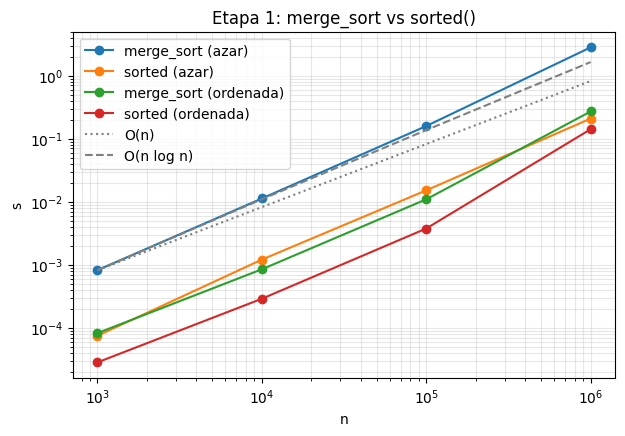

In [ ]:
graficar_loglog(tiempos_orden, "Etapa 1: merge_sort vs sorted()", referencias=("n", "n log n"))

### 1.3 Memoria pico: `merge_sort` vs `sorted()`
`merge_sort` reserva la lista de claves y dos buffers de índices: O(n) extra.

In [ ]:
for n in (10_000, 100_000, 1_000_000):
    xs = [rng.random() for _ in range(n)]
    for nombre, fn in (("merge_sort", lambda: merge_sort(xs, identidad)),
                       ("sorted", lambda: sorted(xs, key=identidad))):
        print(f"n={n:>9,}  {nombre:10} pico {memoria_pico(fn) / 1e6:8.2f} MB")

n=   10,000  merge_sort pico     0.77 MB
n=   10,000  sorted     pico     0.24 MB
n=  100,000  merge_sort pico     7.85 MB
n=  100,000  sorted     pico     2.40 MB
n=1,000,000  merge_sort pico    78.66 MB
n=1,000,000  sorted     pico    24.00 MB


### 1.4 Búsqueda: `busqueda_binaria` vs `bisect` vs `in set`
Tiempo por consulta. `bisect` es la misma búsqueda binaria hecha en C; `set` es hash, O(1) promedio.
Alrededor de un 10 % de las consultas está en la lista.

n=    1,000  busqueda_binaria   0.706 µs/consulta
n=    1,000  bisect             0.147 µs/consulta
n=    1,000  in set             0.028 µs/consulta
n=   10,000  busqueda_binaria   0.947 µs/consulta
n=   10,000  bisect             0.205 µs/consulta
n=   10,000  in set             0.024 µs/consulta
n=  100,000  busqueda_binaria   1.690 µs/consulta
n=  100,000  bisect             0.372 µs/consulta
n=  100,000  in set             0.032 µs/consulta
n=1,000,000  busqueda_binaria   2.750 µs/consulta
n=1,000,000  bisect             1.017 µs/consulta
n=1,000,000  in set             0.037 µs/consulta


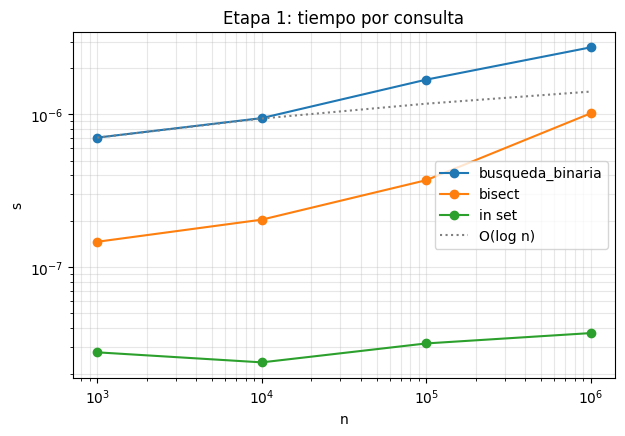

In [ ]:
CONSULTAS = 10_000
tiempos_busqueda = {}
for n in TAMANOS_E1:
    datos = sorted(rng.sample(range(10 * n), n))
    conjunto = set(datos)
    objetivos = [rng.randrange(10 * n) for _ in range(CONSULTAS)]
    casos = {
        "busqueda_binaria": lambda: [busqueda_binaria(datos, x) for x in objetivos],
        "bisect": lambda: [bisect.bisect_left(datos, x) for x in objetivos],
        "in set": lambda: [x in conjunto for x in objetivos],
    }
    for nombre, fn in casos.items():
        prom, _ = medir(fn, 20)
        tiempos_busqueda.setdefault(nombre, {})[n] = prom / CONSULTAS
        print(f"n={n:>9,}  {nombre:16} {prom / CONSULTAS * 1e6:7.3f} µs/consulta")

graficar_loglog(tiempos_busqueda, "Etapa 1: tiempo por consulta", referencias=("log n",))

### 1.5 Deduplicación: `Preprocesador` vs `set` + `deque`
La alternativa exacta y simple guarda las últimas W claves en un `set` y usa una `deque` para saber
cuál vencer. Reutiliza la validación y la clave de `Preprocesador`, así que solo cambia la estructura
de la ventana. Se usa el primer millón de filas reales, en lotes de 10K y ventana de 100K.

In [ ]:
from pipeline_eda.etapa0_ingesta import leer_csv


class DedupSet:
    """Ventana de las últimas `ventana` claves en un set; la deque recuerda el orden para vencerlas."""

    def __init__(self, ventana):
        self.ventana = ventana
        self.vistas = set()
        self.orden = deque()
        self._p = Preprocesador()

    def procesar(self, lote):
        salida = []
        for ev in lote:
            if self._p._motivo_invalido(ev) is not None:
                continue
            k = Preprocesador.clave(self._p._normalizar(ev))
            if k in self.vistas:
                continue
            self.vistas.add(k)
            self.orden.append(k)
            salida.append(ev)
            if len(self.orden) > self.ventana:
                self.vistas.discard(self.orden.popleft())
        return salida


N_DEDUP, TAM_LOTE, VENTANA = 1_000_000, 10_000, 100_000
eventos = list(islice(leer_csv(CSV_REAL), N_DEDUP))
lotes = [eventos[i:i + TAM_LOTE] for i in range(0, len(eventos), TAM_LOTE)]


def correr(clase):
    d = clase(VENTANA)
    return [ev for lote in lotes for ev in d.procesar(lote)], d


salida_pre, pre = correr(Preprocesador)
salida_set, _ = correr(DedupSet)
assert sorted(map(Preprocesador.clave, salida_pre)) == sorted(map(Preprocesador.clave, salida_set))
print(f"Misma salida: {len(salida_pre):,} eventos emitidos de {len(eventos):,}")
pre.metricas()

In [ ]:
for nombre, clase in (("Preprocesador (lista ordenada + búsqueda binaria)", Preprocesador),
                     ("DedupSet (set + deque)", DedupSet)):
    prom, desv = medir(lambda: correr(clase), 3)
    pico = memoria_pico(lambda: correr(clase))
    print(f"{nombre:50} {prom:6.2f} s ± {desv:.2f}   pico {pico / 1e6:7.1f} MB")

Preprocesador (lista ordenada + búsqueda binaria)    4.25 s ± 0.16   pico   104.2 MB
DedupSet (set + deque)                               1.17 s ± 0.22   pico   105.7 MB


## Etapa 2 — Cola con prioridades *(pendiente)*

- `HeapMin` vs `heapq`: push/pop de n elementos (1K–1M), log-log; mismo orden de salida.
- Desempate por orden de llegada entre elementos de igual prioridad.

## Etapa 3 — Hash table, LRU y matriz dispersa *(pendiente)*

- `TablaHash` vs `dict`: inserción y búsqueda, factor de carga.
- `CacheLRU` vs `collections.OrderedDict` / `functools.lru_cache`: tasa de aciertos y tiempo.
- `MatrizDispersa` vs `dict` de `dict`: memoria y tiempo de acceso.

## Etapa 4 — B+Tree

Pruebas traídas de los scripts `probar_*.py` y `benchmark_bplustree.py` de la rama
`mi-trabajo-etapas-4-5-7`, convertidas a `assert`.

### 4.1 `BPlusTree`: búsqueda, rangos y claves repetidas
Orden 4 para forzar divisiones con pocas claves.

In [ ]:
from pipeline_eda.etapa4_bplustree import BPlusTree, IndiceProductos
from pipeline_eda.evento import Event

# Claves desordenadas y una repetida
arbol = BPlusTree(orden=4)
for clave, valor in [(50, "A"), (20, "B"), (40, "C"), (10, "D"), (30, "E"), (20, "F"), (60, "G")]:
    arbol.insertar(clave, valor)

assert arbol.buscar(20) == ["B", "F"]
assert arbol.buscar(999) == []
assert list(arbol.rango(10, 60)) == [(10, "D"), (20, "B"), (20, "F"), (30, "E"), (40, "C"), (50, "A"), (60, "G")]
assert list(arbol.rango(70, 90)) == []                                 # sin resultados
assert list(arbol.rango(50, 20)) == []                                 # rango invertido
assert list(arbol.rango(20, 20)) == [(20, "B"), (20, "F")]             # una sola clave
assert list(arbol.rango(20, 35)) == [(20, "B"), (20, "F"), (30, "E")]  # un extremo no existe
assert arbol.metricas()["claves_indexadas"] == 6
arbol.metricas()

In [ ]:
# Muchas inserciones en orden con orden 4: el árbol crece en altura
for n in (100, 10_000):
    arbol = BPlusTree(orden=4)
    for i in range(1, n + 1):
        arbol.insertar(i, f"producto_{i}")
    assert arbol.metricas()["claves_indexadas"] == n
    assert arbol.buscar(n * 3 // 4) == [f"producto_{n * 3 // 4}"]
    assert list(arbol.rango(n // 2, n // 2 + 5)) == [(i, f"producto_{i}") for i in range(n // 2, n // 2 + 6)]
    print(f"n={n:>6,}", arbol.metricas())

In [ ]:
# Contra una referencia de Python: dict clave -> valores, y rangos sobre sorted()
rng = random.Random(SEED)
for orden in (3, 4, 64):
    arbol, ref = BPlusTree(orden=orden), {}
    for i in range(5_000):
        clave = rng.randint(0, 2_000)
        arbol.insertar(clave, i)
        ref.setdefault(clave, []).append(i)
    for _ in range(200):
        a, b = sorted(rng.randint(-10, 2_010) for _ in range(2))
        assert list(arbol.rango(a, b)) == [(k, v) for k in sorted(ref) if a <= k <= b for v in ref[k]]
        assert arbol.buscar(a) == ref.get(a, [])
print("BPlusTree == dict + sorted() en buscar y rango (órdenes 3, 4 y 64)")

### 4.2 `IndiceProductos`: cambios de precio, NaN y precios límite

In [ ]:
def evento(tiempo, producto, precio):
    return Event(event_time=tiempo, event_type="view", product_id=producto, category_id=1,
                 category_code=None, brand=None, price=precio, user_id=100 + producto,
                 user_session=f"sesion_{producto}")


# Cambios de precio: solo cuenta el precio actual de cada producto
indice = IndiceProductos(orden=4)
for t, prod, precio in [(100, 1, 10.0), (200, 2, 20.0), (300, 1, 15.0), (300, 3, 15.0)]:
    indice.consumir(evento(t, prod, precio))
assert indice.productos_en_rango_precio(15.0, 15.0) == [1, 3]
assert indice.productos_en_rango_precio(10.0, 10.0) == []  # precio anterior del producto 1
assert [(e.event_time, e.product_id, e.price) for e in indice.eventos_en_rango_tiempo(200, 300)] == \
    [(200, 2, 20.0), (300, 1, 15.0), (300, 3, 15.0)]

indice.consumir(evento(400, 1, 25.0))
indice.consumir(evento(500, 1, 30.0))
assert indice.productos_en_rango_precio(30.0, 30.0) == [1]
assert indice.productos_en_rango_precio(25.0, 25.0) == []
assert indice.productos_en_rango_precio(15.0, 15.0) == [3]
assert [(e.event_time, e.price) for e in indice.eventos_en_rango_tiempo(100, 500) if e.product_id == 1] == \
    [(100, 10.0), (300, 15.0), (400, 25.0), (500, 30.0)]  # historial del producto 1
indice.metricas()

In [ ]:
# NaN y negativos no se indexan por precio: el producto conserva su último precio válido
indice = IndiceProductos(orden=4)
indice.consumir(evento(100, 1, 25.0))
indice.consumir(evento(200, 1, float("nan")))
indice.consumir(evento(300, 1, -5.0))
assert indice.productos_en_rango_precio(25, 25) == [1]
assert indice.productos_en_rango_precio(-10, -1) == []

# Precio 0 sí se indexa (en el pipeline la etapa 1 ya descarta precio <= 0)
indice = IndiceProductos(orden=4)
for prod, precio in [(1, 0.0), (2, -5.0), (3, 10.0)]:
    indice.consumir(evento(100, prod, precio))
assert indice.productos_en_rango_precio(0, 0) == [1]
assert indice.productos_en_rango_precio(-10, -1) == []
assert indice.productos_en_rango_precio(1, 20) == [3]
print("IndiceProductos OK")

### 4.3 Volumen de `IndiceProductos`
1.000 productos con 20 precios posibles; cada evento entra al índice de tiempo.

In [ ]:
for n in (10_000, 100_000):
    indice = IndiceProductos(orden=64)
    inicio = time.perf_counter()
    for i in range(n):
        producto = (i % 1000) + 1
        indice.consumir(evento(i, producto, 10.0 + (i % 20)))
    m = indice.metricas()
    print(f"n={n:>7,}  {time.perf_counter() - inicio:.3f} s  productos={m['productos_indexados']}  "
          f"claves precio={m['arbol_precio']['claves_indexadas']} (altura {m['arbol_precio']['altura']})  "
          f"claves tiempo={m['arbol_tiempo']['claves_indexadas']:,} (altura {m['arbol_tiempo']['altura']})")

### 4.4 B+Tree vs lista ordenada + `bisect`
Mismos datos y mismo orden de inserción (al azar) para ambas estructuras.

- **Corrección respecto de `benchmark_bplustree.py`:** allí las consultas llamaban a `arbol.rango(...)`
  sin consumir el generador, así que la búsqueda no llegaba a ejecutarse y el B+Tree aparecía 10–20x
  más rápido. Aquí se consume con `list(...)`, y la búsqueda exacta usa `buscar`. Los números fijos de
  `resumen_benchmark.py` se reemplazan por esta medición.
- Construir la lista con `insort` es O(n²) por los corrimientos, por eso el tamaño máximo es 200K.

In [ ]:
TAMANOS_E4 = [1_000, 10_000, 100_000, 200_000]
NUM_CONSULTAS, NUM_RANGOS, ANCHO_RANGO = 1_000, 100, 20

construccion, memoria_e4, exacta, por_rango = {}, {}, {}, {}
for n in TAMANOS_E4:
    rng = random.Random(SEED)
    datos = list(range(1, n + 1))
    rng.shuffle(datos)
    consultas = rng.sample(range(1, n + 1), NUM_CONSULTAS)
    rangos = [(x, x + ANCHO_RANGO) for x in consultas[:NUM_RANGOS]]

    def construir_bplus():
        arbol = BPlusTree(orden=64)
        for clave in datos:
            arbol.insertar(clave, clave)
        return arbol

    def construir_lista():
        lista = []
        for clave in datos:
            bisect.insort(lista, (clave, clave))
        return lista

    arbol, lista = construir_bplus(), construir_lista()
    casos = {
        "B+Tree": (construir_bplus,
                   lambda: [arbol.buscar(c) for c in consultas],
                   lambda: [list(arbol.rango(a, b)) for a, b in rangos]),
        "lista + bisect": (construir_lista,
                           lambda: [lista[bisect.bisect_left(lista, (c, -math.inf)):bisect.bisect_right(lista, (c, math.inf))]
                                    for c in consultas],
                           lambda: [lista[bisect.bisect_left(lista, (a, -math.inf)):bisect.bisect_right(lista, (b, math.inf))]
                                    for a, b in rangos]),
    }
    for nombre, (construir, buscar_exacta, buscar_rango) in casos.items():
        t_constr, _ = medir(construir, 3 if n <= 10_000 else 1)
        pico = memoria_pico(construir) if n <= 100_000 else None
        t_exacta, _ = medir(buscar_exacta, 20)
        t_rango, _ = medir(buscar_rango, 20)
        construccion.setdefault(nombre, {})[n] = t_constr
        exacta.setdefault(nombre, {})[n] = t_exacta / NUM_CONSULTAS
        por_rango.setdefault(nombre, {})[n] = t_rango / NUM_RANGOS
        pico_txt = f"{pico / 1e6:6.2f} MB" if pico is not None else "     —   "
        print(f"n={n:>7,}  {nombre:15} construcción {t_constr:8.4f} s  pico {pico_txt}  "
              f"exacta {t_exacta / NUM_CONSULTAS * 1e6:6.2f} µs  rango {t_rango / NUM_RANGOS * 1e6:6.2f} µs")

In [ ]:
graficar_loglog(construccion, "Etapa 4: construcción", referencias=("n log n",))
graficar_loglog({f"{k} (exacta)": v for k, v in exacta.items()} | {f"{k} (rango)": v for k, v in por_rango.items()},
                "Etapa 4: tiempo por consulta", referencias=("log n",))

## Etapa 5 — KD-Tree y KNN exacto *(pendiente)*

- `KDTree` vs `knn_exacto` (fuerza bruta): tiempo por consulta y mismos vecinos.

## Etapa 6 [FIJA] — Bloom Filter y Count-Min Sketch *(pendiente)*

- `BloomFilter` vs `set`: tiempo, memoria y tasa de FP observada vs teórica, 1K–10M.
- `CountMinSketch` vs `dict` / `Counter`: error de frecuencia, memoria y tiempo, 1K–10M.

## Etapa 7 [FIJA] — MinHash + LSH y HNSW *(pendiente)*

- MinHash + LSH vs `jaccard_exacto` por fuerza bruta: tiempo, memoria y calidad, 1K–10M.
- HNSW vs KNN exacto: tiempo, memoria y recall@K, 1K–10M.

## Etapa 8 [FIJA] — PageRank y comunidades *(pendiente)*

- PageRank vs ranking por grado: correlación de rankings y tiempo.
- Comunidades vs alternativa simple: modularidad, tiempo, cantidad y tamaño de comunidades, estabilidad entre semillas.

## Etapa 9 — Trie y Top-K *(pendiente)*

- `Trie` vs búsqueda de prefijo en lista ordenada + `bisect`.
- `TopK` vs `heapq.nlargest` y `sorted()[:k]`.